<a href="https://colab.research.google.com/github/andreacecchini/ml-dojo/blob/main/playground.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Playground


In [26]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from torchvision import transforms

In [27]:
data_dir = "./data"

transform = transforms.ToTensor()
# Train dataset
train = torchvision.datasets.FashionMNIST(
    data_dir,
    train=True,
    download=True,
    transform=transform
    )
# Test dataset
test = torchvision.datasets.FashionMNIST(
    data_dir,
    train=False,
    download=True,
    transform=transform
    )

print("Training: ", len(train))
print("Testing: ", len(test))


Training:  60000
Testing:  10000


Dimension:  torch.Size([1, 28, 28])
Label:  9


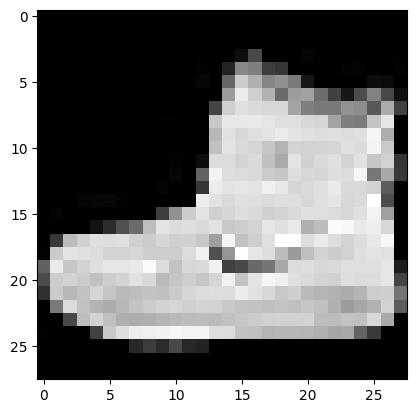

In [41]:
image, label = train[0]
print("Dimension: ", image.shape)
print("Label: ", label)

plt.imshow(image.squeeze(), cmap="gray")
plt.show()

In [87]:
# T-shirts
X_train_0 = torch.stack([
    x[0] * 256 for x in train if x[1] == 0
  ])
# Trousers
X_train_1 = torch.stack([
  x[0] * 256 for x in train if x[1] == 1
  ])
X_test = torch.stack([
    x[0] * 256 for x in test if x[1] in (0, 1)
])
y_test = torch.tensor([
    x[1] for x in test if x[1] in (0, 1)
])
print(X_test.shape)

torch.Size([2000, 1, 28, 28])

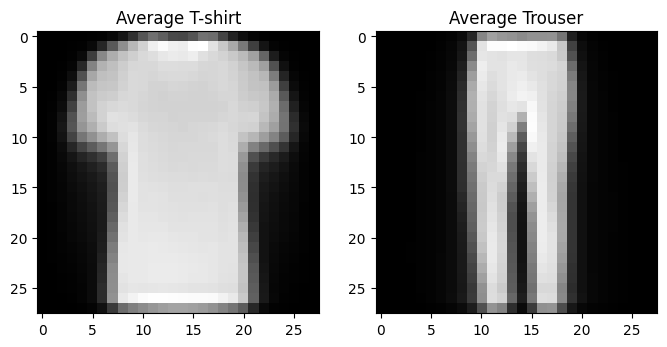

In [88]:
# Avg
avg_0 = torch.mean(X_train_0, axis=0)
avg_1 = torch.mean(X_train_1, axis=0)
# Visualize
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(avg_0.squeeze(), cmap="gray")
axes[0].set_title("Average T-shirt")
axes[1].imshow(avg_1.squeeze(), cmap="gray")
axes[1].set_title("Average Trouser")
plt.show()

## Method 1

In [92]:
# Normal vector w.r.t decision plan
w = (avg_1 - avg_0).flatten()
threshold = -1500000
prediction = (
    X_test.reshape(2000, -1) @ w > threshold
)
accuracy = (prediction == y_test).float().mean()
print("Accuracy: ", accuracy.item())

Accuracy:  0.8730000257492065


## Method 2

In [93]:
# Normalize means and images
avg_0 = avg_0.flatten()
avg_1 = avg_1.flatten()
avg_0_norm = avg_0 / torch.norm(avg_0)
avg_1_norm = avg_1 / torch.norm(avg_1)
X_test = X_test.reshape(2000, -1)
X_test_norm = X_test / torch.norm(X_test, dim=1, keepdim=True)
# Compute similarity
W = torch.stack([avg_0_norm, avg_1_norm], dim=1)
scores = X_test @ W
predictions = scores.argmax(dim=1)
accuracy = (predictions == y_test).float().mean()
print("Accuracy: ", accuracy.item())

Accuracy:  0.9474999904632568
